# A8 evaluation: metrics, comparison tables and failure analysis

INFO 490 MG, Team 15. Evaluation by Hriday Agarwal.

This notebook does not run any models. It reads the results of Connor's full run of
`../rag_system.ipynb` (9 setups x 14 queries, saved in `../results/`) and the manual grades in this
folder, then builds every number used in `../rag_analysis.md`.

**Why manual grades.** The run's `_auto` columns match expected phrases, and its `context_hit`
counts a chunk as a hit if it touches the expected section. Both are useful but rough, so every
row was also graded by hand after reading the retrieved chunks and the answer:

| Column | Good | Partial | Poor |
| --- | --- | --- | --- |
| `context_quality_manual` | The top 3 chunks contain the sentences needed to answer | They contain only some of them | The needed text was not retrieved |
| `answer_quality_manual` | Correct and faithful to the documents | Core is right, but incomplete, padded with off-topic text, or has a misstatement | Wrong, invented, or refuses a question the documents answer |

Out-of-scope queries (q13, q14) get `N/A` for context; their answer is Good only if the model refused.
Each grade has a one-line note in `manual_grades.csv` saying why.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

RESULTS = Path("../results")
QUERIES = json.loads(Path("../test_queries.json").read_text())
DIFFICULTY = {q["id"]: q.get("difficulty", "out of scope" if q.get("out_of_scope") else "?") for q in QUERIES}
OUT_OF_SCOPE = {q["id"] for q in QUERIES if q.get("out_of_scope")}
MODELS = ["small", "medium", "large"]
STRATEGIES = ["fixed", "hybrid", "overlap"]
SCORE = {"Good": 1.0, "Partial": 0.5, "Poor": 0.0}

raw = pd.read_csv(RESULTS / "evaluation_table.csv")
grades = pd.read_csv("manual_grades.csv")
keys = ["embedding_model", "chunking_strategy", "query_id"]
table = raw.drop(columns=["context_quality_manual", "answer_quality_manual", "notes"]).merge(
    grades, on=keys, how="left", validate="one_to_one")
assert len(table) == 126 and table["answer_quality_manual"].notna().all(), "every row must be graded"
table["difficulty"] = table["query_id"].map(DIFFICULTY)
table["answerable"] = ~table["query_id"].isin(OUT_OF_SCOPE)
table["answer_score"] = table["answer_quality_manual"].map(SCORE)
table["reciprocal_rank"] = (1 / table["first_hit_rank"]).fillna(0.0)
table["wrong_refusal"] = table["answerable"] & table["declined"]

# The graded evaluation table: the run's table with the manual columns filled in.
graded = raw[[c for c in raw.columns if c not in ("context_quality_manual", "answer_quality_manual", "notes")]].merge(
    grades, on=keys, how="left")
graded.to_csv("evaluation_table_graded.csv", index=False)
print("Graded rows:", len(table), "| answerable:", int(table["answerable"].sum()),
      "| out of scope:", int((~table["answerable"]).sum()))
print("Saved evaluation_table_graded.csv")

Graded rows: 126 | answerable: 108 | out of scope: 18
Saved evaluation_table_graded.csv


## Step 2.2: Evaluation metrics

| Metric | How it is computed | What it tells us |
| --- | --- | --- |
| **Hit@3 (auto)** | Share of answerable queries where a top-3 chunk touches the expected section (the run's `context_hit`) | Did retrieval land in the right place at all? |
| **MRR@3** | Mean of 1 / rank of the first hit (0 if missed) | How high the right chunk ranked |
| **Context Good (manual)** | Share of answerable queries whose top 3 actually contain the answering sentences | Could the model have answered from what it was given? |
| **Answer score (manual)** | Good = 1, Partial = 0.5, Poor = 0, averaged, as a % | Overall answer quality |
| **Answer Good (manual)** | Share of answerable queries answered Good | How often the answer was fully right |
| **Wrong refusals** | Answerable queries the model refused | Over-cautious generation |
| **Correct refusals** | Out-of-scope queries the model refused (of 2) | Hallucination guard |
| **Latency** | Mean search ms and generation s (from the run) | Cost per query |

Retrieval metrics and answer metrics use the 12 answerable queries; refusals of out-of-scope
queries are counted separately.

In [2]:
def summarise(frame, by):
    ans = frame[frame["answerable"]]
    oos = frame[~frame["answerable"]]
    out = ans.groupby(by, sort=False).agg(
        hit_at_3=("context_hit", "mean"),
        mrr_at_3=("reciprocal_rank", "mean"),
        context_good=("context_quality_manual", lambda s: (s == "Good").mean()),
        answer_score=("answer_score", "mean"),
        answer_good=("answer_quality_manual", lambda s: (s == "Good").mean()),
        answer_poor=("answer_quality_manual", lambda s: (s == "Poor").mean()),
        wrong_refusals=("wrong_refusal", "sum"),
        search_ms=("search_ms", "mean"),
        generate_s=("generate_s", "mean"),
    )
    out["correct_refusals"] = oos.groupby(by, sort=False)["declined"].sum()
    for col in ("hit_at_3", "context_good", "answer_score", "answer_good", "answer_poor"):
        out[col] = (out[col] * 100).round(1)
    return out.round({"mrr_at_3": 3, "search_ms": 1, "generate_s": 2})


by_config = summarise(table, ["embedding_model", "chunking_strategy"]).reindex(
    pd.MultiIndex.from_product([MODELS, STRATEGIES], names=["embedding_model", "chunking_strategy"]))
by_config.to_csv("summary_by_config_manual.csv")
by_config

hit_at_3  mrr_at_3  context_good  answer_score  answer_good  answer_poor  wrong_refusals  search_ms  generate_s  correct_refusals
embedding_model chunking_strategy                                                                                                                                   
small           fixed                 100.0     0.903          83.3          45.8         25.0         33.3               3        4.9        0.82                 2
                hybrid                100.0     0.917         100.0          54.2         41.7         33.3               3        5.5        1.27                 2
                overlap                83.3     0.792          83.3          45.8         25.0         33.3               2        5.0        1.53                 2
medium          fixed                 100.0     0.875          91.7          45.8         25.0         33.3               3        9.8        1.06                 2
                hybrid                100.0     0.861         100.0          45.8         25.0         33.3               3        8.0        0.90                 2
                overlap                91.7     0.875          91.7          54.2         33.3         25.0               2        9.4        1.63                 2
large           fixed                 100.0     0.903          83.3          45.8         25.0         33.3               3       16.0        0.85                 2
                hybrid                 83.3     0.750          83.3          50.0         41.7         41.7               3       15.8        1.01                 2
                overlap                83.3     0.833          83.3          54.2         33.3         25.0               2       16.2        1.34                 2

## Step 2.3: Embedding models (averaged over the three chunking strategies)

In [3]:
by_model = summarise(table, ["embedding_model"]).reindex(MODELS)
by_model.to_csv("summary_by_model_manual.csv")
by_model

,hit_at_3,mrr_at_3,context_good,answer_score,answer_good,answer_poor,wrong_refusals,search_ms,generate_s,correct_refusals
embedding_model,,,,,,,,,,
small,94.4,0.870,88.9,48.6,30.6,33.3,8,5.1,1.21,6
medium,97.2,0.870,94.4,48.6,27.8,30.6,8,9.1,1.19,6
large,88.9,0.829,83.3,50.0,33.3,33.3,8,16.0,1.07,6


## Step 2.4: Chunking strategies (averaged over the three embedding models)

In [4]:
by_strategy = summarise(table, ["chunking_strategy"]).reindex(STRATEGIES)
by_strategy.to_csv("summary_by_strategy_manual.csv")
by_strategy

,hit_at_3,mrr_at_3,context_good,answer_score,answer_good,answer_poor,wrong_refusals,search_ms,generate_s,correct_refusals
chunking_strategy,,,,,,,,,,
fixed,100.0,0.894,86.1,45.8,25.0,33.3,9,10.2,0.91,6
hybrid,94.4,0.843,94.4,50.0,36.1,36.1,9,9.8,1.06,6
overlap,86.1,0.833,86.1,51.4,30.6,27.8,6,10.2,1.50,6


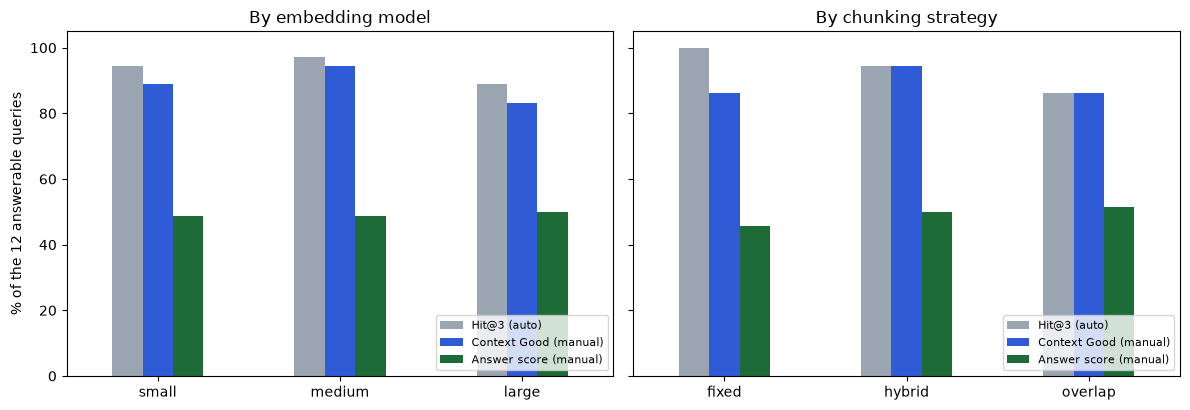

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, frame, title in ((axes[0], by_model, "By embedding model"), (axes[1], by_strategy, "By chunking strategy")):
    frame[["hit_at_3", "context_good", "answer_score"]].plot.bar(
        ax=ax, rot=0, color=["#9aa5b1", "#2f5bd7", "#1d6b36"])
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylim(0, 105)
    ax.legend(["Hit@3 (auto)", "Context Good (manual)", "Answer score (manual)"], fontsize=8, loc="lower right")
axes[0].set_ylabel("% of the 12 answerable queries")
plt.tight_layout()
plt.savefig("comparison_chart.png", dpi=120)
plt.show()

### Answer score by query difficulty

Each cell averages the 9 setups (or the 3 setups of one model or strategy) on that difficulty band.

In [6]:
ans = table[table["answerable"]]
difficulty = pd.concat({
    "all setups": ans.groupby("difficulty")["answer_score"].mean(),
    **{f"model: {m}": ans[ans.embedding_model == m].groupby("difficulty")["answer_score"].mean() for m in MODELS},
    **{f"chunking: {s}": ans[ans.chunking_strategy == s].groupby("difficulty")["answer_score"].mean() for s in STRATEGIES},
}, axis=1).reindex(["easy", "medium", "hard"]).mul(100).round(1)
difficulty.to_csv("answer_score_by_difficulty.csv")
difficulty

,all setups,model: small,model: medium,model: large,chunking: fixed,chunking: hybrid,chunking: overlap
difficulty,,,,,,,
easy,72.2,72.2,72.2,72.2,50.0,83.3,83.3
medium,51.4,45.8,50.0,58.3,58.3,45.8,50.0
hard,33.3,36.7,33.3,30.0,33.3,33.3,33.3


In [7]:
# Answer grade for every query in every setup (G = Good, P = Partial, X = Poor).
letter = {"Good": "G", "Partial": "P", "Poor": "X"}
grid = table.assign(setup=table["embedding_model"] + "/" + table["chunking_strategy"]).pivot(
    index="query_id", columns="setup", values="answer_quality_manual").replace(letter)
grid = grid[[f"{m}/{s}" for m in MODELS for s in STRATEGIES]]
grid.insert(0, "difficulty", grid.index.map(DIFFICULTY))
grid

setup,difficulty,small/fixed,small/hybrid,small/overlap,medium/fixed,medium/hybrid,medium/overlap,large/fixed,large/hybrid,large/overlap
query_id,,,,,,,,,,
q01,easy,G,G,G,G,G,G,G,G,G
q02,easy,P,P,P,P,P,P,P,P,P
q03,easy,X,G,G,X,G,G,X,G,G
q04,medium,P,G,X,P,P,P,P,P,X
q05,medium,P,G,P,G,P,G,G,G,G
q06,medium,G,X,P,G,X,P,G,G,P
q07,medium,X,X,P,X,X,P,X,X,P
q08,hard,X,P,X,X,X,X,X,X,X
q09,hard,P,P,X,P,P,X,P,X,P


## How far the automatic scores can be trusted

The run's automatic scores are a first pass. Comparing them with the manual grades shows where
they go wrong, which matters for anyone reading `summary_by_*.csv` on its own.

In [8]:
answer_agreement = pd.crosstab(ans["answer_quality_auto"], ans["answer_quality_manual"],
                               rownames=["auto"], colnames=["manual"]).reindex(
    index=["Good", "Partial", "Poor"], columns=["Good", "Partial", "Poor"], fill_value=0)
agree = (ans["answer_quality_auto"] == ans["answer_quality_manual"]).mean()
print(f"Answer quality: auto and manual agree on {agree:.0%} of the 108 answerable rows")
display(answer_agreement)

hits_without_answer = ans[(ans["context_hit"] == 1) & (ans["context_quality_manual"] != "Good")]
print(f"\nRows counted as a hit by the auto metric whose chunks did not contain the full answer: "
      f"{len(hits_without_answer)}")
display(hits_without_answer[keys + ["first_hit_rank", "context_quality_manual", "notes"]])

auto_good_manual_poor = ans[(ans["answer_quality_auto"] == "Good") & (ans["answer_quality_manual"] == "Poor")]
print("\nAuto said Good, manual said Poor:")
display(auto_good_manual_poor[keys + ["notes"]])

Answer quality: auto and manual agree on 63% of the 108 answerable rows


manual,Good,Partial,Poor
auto,,,
Good,20,4,2
Partial,12,16,1
Poor,1,20,32



Rows counted as a hit by the auto metric whose chunks did not contain the full answer: 5


,embedding_model,chunking_strategy,query_id,first_hit_rank,context_quality_manual,notes
2,small,fixed,q03,1.0,Poor,Says 'three statuses: one of three statuses'. Fixed chunk ends at 'has one of three statuses.'; the statuses are in ...
11,small,fixed,q12,1.0,Partial,Wrong refusal. The fixed chunk has only the section's first sentence ('suspect the rule or the export'); the causes ...
44,medium,fixed,q03,1.0,Partial,"Wrong fact: 'active, history, and draft'. Fixed chunk ends at 'has one of three statuses.'; the statuses are in the ..."
86,large,fixed,q03,1.0,Poor,"Invents 'unique per dataset, version three'. Fixed chunk ends at 'has one of three statuses.'; the statuses are in t..."
95,large,fixed,q12,1.0,Partial,Wrong refusal. The fixed chunk has only the section's first sentence ('suspect the rule or the export'); the causes ...



Auto said Good, manual said Poor:


,embedding_model,chunking_strategy,query_id,notes
22,small,overlap,q09,Recommends CSV even though the same chunk says JSON suits programs. Auto score said Good.
64,medium,overlap,q09,Recommends CSV even though the same chunk says JSON suits programs. Auto score said Good.


## Step 3.1 and 3.2: Where the failures come from

Every answerable row graded Poor is put in one bucket:

* **Retrieval failure**: the answering text was not retrieved (context Poor or Partial), so the
  model could not have answered.
* **Generation failure**: the answering text was retrieved (context Good), but the model refused,
  misread it, or answered something else.

In [9]:
poor = ans[ans["answer_quality_manual"] == "Poor"].copy()
poor["cause"] = poor["context_quality_manual"].map(lambda c: "generation" if c == "Good" else "retrieval")
poor["kind"] = "wrong or invented content"
poor.loc[poor["declined"], "kind"] = "refused an answerable question"
causes = pd.crosstab(poor["cause"], poor["kind"], margins=True, margins_name="total")
print(f"Poor answers on answerable queries: {len(poor)} of {len(ans)}")
display(causes)
display(poor.groupby("query_id")["cause"].value_counts().unstack(fill_value=0))

Poor answers on answerable queries: 35 of 108


kind,refused an answerable question,wrong or invented content,total
cause,,,
generation,13,11,24
retrieval,2,9,11
total,15,20,35


cause,generation,retrieval
query_id,,
q03,0,3
q04,0,2
q06,2,0
q07,6,0
q08,5,3
q09,2,1
q10,1,0
q11,1,0
q12,7,2


## Step 3.3: Improvement attempt, graded by hand

Connor's run tried three changes on the best setup (medium + fixed), one at a time. The baseline
rows are identical to medium + fixed in the main table (checked below).

In [10]:
improvement = pd.read_csv(RESULTS / "improvement_results.csv")
igrades = pd.read_csv("manual_grades_improvement.csv")
imp = improvement.merge(igrades, on=["variant", "query_id"], how="left", validate="one_to_one")
assert imp["answer_quality_manual"].notna().all()
base = imp[imp.variant == "baseline"].set_index("query_id")["answer"]
mf = table[(table.embedding_model == "medium") & (table.chunking_strategy == "fixed")].set_index("query_id")["answer"]
print("Baseline identical to main-table medium/fixed:", all(base[q].strip() == mf[q].strip() for q in base.index))

imp["answerable"] = ~imp["query_id"].isin(OUT_OF_SCOPE)
imp["answer_score"] = imp["answer_quality_manual"].map(SCORE)
order = ["baseline", "top_k_1", "top_k_5", "strict_prompt"]
a = imp[imp["answerable"]]
before_after = pd.DataFrame({
    "hit_at_k (auto)": a.groupby("variant")["context_hit"].mean().mul(100).round(1),
    "answer_score (manual)": a.groupby("variant")["answer_score"].mean().mul(100).round(1),
    "Good": a.groupby("variant")["answer_quality_manual"].apply(lambda s: (s == "Good").sum()),
    "Partial": a.groupby("variant")["answer_quality_manual"].apply(lambda s: (s == "Partial").sum()),
    "Poor": a.groupby("variant")["answer_quality_manual"].apply(lambda s: (s == "Poor").sum()),
    "wrong refusals": a.groupby("variant")["declined"].sum(),
    "out-of-scope refused (of 2)": imp[~imp["answerable"]].groupby("variant")["declined"].sum(),
    "generate_s": imp.groupby("variant")["generate_s"].mean().round(2),
}).reindex(order)
before_after.to_csv("improvement_manual.csv")
before_after

Baseline identical to main-table medium/fixed: True


,hit_at_k (auto),answer_score (manual),Good,Partial,Poor,wrong refusals,out-of-scope refused (of 2),generate_s
variant,,,,,,,,
baseline,100.0,45.8,3,5,4,3,2,0.86
top_k_1,75.0,41.7,3,4,5,4,2,0.65
top_k_5,100.0,58.3,4,6,2,3,2,0.82
strict_prompt,100.0,62.5,5,5,2,0,2,0.67


In [11]:
# Per-query before/after for the baseline and the strict prompt.
compare = imp[imp.variant.isin(["baseline", "strict_prompt"])].pivot(
    index="query_id", columns="variant", values="answer_quality_manual")[["baseline", "strict_prompt"]]
compare["changed"] = compare["baseline"] != compare["strict_prompt"]
compare

variant,baseline,strict_prompt,changed
query_id,,,
q01,Good,Good,False
q02,Partial,Good,True
q03,Poor,Poor,False
q04,Partial,Partial,False
q05,Good,Good,False
q06,Good,Good,False
q07,Poor,Partial,True
q08,Poor,Poor,False
q09,Partial,Good,True


## Step 2.5: Data scaling (from the run, best setup)

Not re-graded: these are retrieval-only measurements. Shown here so `rag_analysis.md` can cite them.

In [12]:
scaling = pd.read_csv(RESULTS / "scaling_results.csv")
scaling_summary = scaling.groupby("share_of_data").agg(
    chunks=("chunks", "mean"), hit_rate=("hit", "mean"), noise=("noise", "mean"),
    mean_margin=("margin", "mean"), negative_margins=("margin", lambda m: int((m < 0).sum())))
scaling_summary["hit_rate"] = (scaling_summary["hit_rate"] * 100).round(1)
scaling_summary["noise"] = (scaling_summary["noise"] * 100).round(1)
scaling_summary = scaling_summary.round({"chunks": 1, "mean_margin": 3})
scaling_summary.to_csv("scaling_summary.csv")
scaling_summary

,chunks,hit_rate,noise,mean_margin,negative_margins
share_of_data,,,,,
0.25,11.3,100.0,50.0,0.223,0
0.50,20.8,100.0,50.0,0.186,2
1.00,40.0,100.0,55.6,0.128,3


## Step 2.2: The full evaluation table as Markdown

The assignment's evaluation table, one section per configuration, with the columns it asks for:
query, retrieved chunks (rank, source section and similarity score), retrieved context quality,
answer quality, latency and notes. This cell writes `evaluation_table_full.md`, which is copied into
`rag_analysis.md` as Appendix A. The full chunk text and every answer are in
`evaluation_table_graded.csv`.

In [13]:
import re


def chunk_list(text):
    found = re.findall(r"\[(\d)\] \(([\d.]+)\) ([^:\n]+?):", str(text))
    return "<br>".join(f"{rank}. {label.strip()} ({score})" for rank, score, label in found)


def cell(text):
    return str(text).replace("|", "/").replace("\n", " ")


lines = []
for m in MODELS:
    for s in STRATEGIES:
        rows = table[(table.embedding_model == m) & (table.chunking_strategy == s)].sort_values("query_id")
        lines += [f"#### {m} embeddings + {s} chunking", "",
                  "| Query | Retrieved chunks (rank. section (score)) | Context quality | Answer quality | Latency | Notes |",
                  "| --- | --- | --- | --- | --- | --- |"]
        for _, r in rows.iterrows():
            latency = f"{r['total_s']:.2f} s ({r['search_ms']:.0f} ms search)"
            lines.append(f"| {r['query_id']}: {cell(r['query'])} | {chunk_list(r['retrieved_chunks'])} | "
                         f"{r['context_quality_manual']} | {r['answer_quality_manual']} | {latency} | {cell(r['notes'])} |")
        lines.append("")
Path("evaluation_table_full.md").write_text("\n".join(lines))
print("Wrote evaluation_table_full.md:", sum(l.startswith("| q") for l in lines), "rows in 9 tables")

Wrote evaluation_table_full.md: 126 rows in 9 tables


## Output files

| File | Contents |
| --- | --- |
| `manual_grades.csv`, `manual_grades_improvement.csv` | The hand grades and a note for every row |
| `evaluation_table_graded.csv` | The run's evaluation table with the manual columns filled in |
| `evaluation_table_full.md` | The same table as Markdown, one section per configuration (Appendix A of `rag_analysis.md`) |
| `summary_by_config_manual.csv`, `summary_by_model_manual.csv`, `summary_by_strategy_manual.csv` | Steps 2.3 and 2.4 |
| `answer_score_by_difficulty.csv` | Answer score by difficulty band |
| `improvement_manual.csv` | Step 3.3 before and after |
| `scaling_summary.csv` | Step 2.5 averages |
| `comparison_chart.png` | Model and chunking comparison chart |